In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from pathlib import Path
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, roc_auc_score, average_precision_score
warnings.filterwarnings('ignore')

BASE_DIR = Path('../outputs/hybrid')
FIG_DIR = Path('../figures')
TAB_DIR = Path('../tables')
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    'figure.dpi': 150, 'font.size': 11, 'font.family': 'serif',
    'axes.spines.top': False, 'axes.spines.right': False,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
})
print("Setup complete.")

Setup complete.


In [2]:
import pandas as pd
import numpy as np
from pathlib import Path

# Load CSV
df = pd.read_csv("../outputs/hybrid/final_hybrid_predictions_train_calibrated.csv")


y_true       = df['y_true'].values
xgb_raw      = df['xgb_proba'].values
xgb_cal      = df['calibrated_xgb_proba'].values
vqc_raw      = df['vqc_proba'].values
vqc_cal      = df['calibrated_vqc_proba'].values
hybrid_score = df['hybrid_score'].values


print("=== VERIFICATION ===")
print(f"XGB raw : [{xgb_raw.min():.4f}, {xgb_raw.max():.4f}]")
print(f"XGB cal : [{xgb_cal.min():.4f}, {xgb_cal.max():.4f}]")
print(f"VQC raw : [{vqc_raw.min():.4f}, {vqc_raw.max():.4f}]")
print(f"VQC cal : [{vqc_cal.min():.4f}, {vqc_cal.max():.4f}]")
print(f"Hybrid  : [{hybrid_score.min():.4f}, {hybrid_score.max():.4f}]")


from sklearn.metrics import roc_auc_score
print(f"\nROC-AUC check:")
print(f"  XGB raw:  {roc_auc_score(y_true, xgb_raw)*100:.2f}%")
print(f"  XGB cal:  {roc_auc_score(y_true, xgb_cal)*100:.2f}%")
print(f"  VQC raw:  {roc_auc_score(y_true, vqc_raw)*100:.2f}%")
print(f"  VQC cal:  {roc_auc_score(y_true, vqc_cal)*100:.2f}%")
print(f"  Hybrid:   {roc_auc_score(y_true, hybrid_score)*100:.2f}%")


vqc_auc = roc_auc_score(y_true, vqc_cal)
if vqc_auc < 0.50:
    print("\n⚠ STOP — VQC cal AUC below 50%. CSV has wrong calibrated_vqc_proba column.")
    print("  The CSV on disk does not match what you computed in the other notebook.")
    print("  You must resave the CSV before running calibration analysis.")
elif abs(xgb_cal.max() - vqc_cal.max()) < 0.001:
    print("\n⚠ STOP — XGB cal max = VQC cal max. Wrong CSV.")
else:
    print("\n✓ All checks passed. Proceed with calibration analysis.")

=== VERIFICATION ===
XGB raw : [0.0023, 0.9625]
XGB cal : [0.0000, 0.9839]
VQC raw : [0.2041, 0.7980]
VQC cal : [0.2041, 0.7980]
Hybrid  : [0.1021, 0.8910]

ROC-AUC check:
  XGB raw:  87.33%
  XGB cal:  87.48%
  VQC raw:  84.07%
  VQC cal:  84.07%
  Hybrid:   88.13%

✓ All checks passed. Proceed with calibration analysis.


In [3]:
def fit_q_cal(probs, y, n_bins=10):
    """
    Fit quantile calibrator.
    calibration_curve returns (fraction_of_positives, mean_predicted_value)
    We need mean_predicted_value as x-axis and fraction_of_positives as y-axis.
    """
    fraction_pos, mean_pred = calibration_curve(
        y, probs, n_bins=n_bins, strategy='quantile'
    )
    
    sort_idx   = np.argsort(mean_pred)
    mean_pred  = mean_pred[sort_idx]
    fraction_pos = fraction_pos[sort_idx]

    
    mean_pred_pad  = np.concatenate([[0.0],            mean_pred,    [1.0]])
    frac_pos_pad   = np.concatenate([[fraction_pos[0]], fraction_pos, [fraction_pos[-1]]])

    return mean_pred_pad, frac_pos_pad


def apply_q_cal(probs, mean_pred_pad, frac_pos_pad):
    """Apply fitted calibrator to new probabilities."""
    return np.clip(np.interp(probs, mean_pred_pad, frac_pos_pad), 0.0, 1.0)

In [4]:
def compute_ece(y_true, y_prob, n_bins=10, strategy='quantile'):
    """Compute Expected Calibration Error."""
    if strategy == 'quantile':
        quantiles = np.linspace(0, 1, n_bins + 1)
        bins = np.percentile(y_prob, quantiles * 100)
    else:
        bins = np.linspace(0, 1, n_bins + 1)

    ece = 0.0
    n = len(y_true)
    bin_data = []

    for i in range(len(bins) - 1):
        if i == 0:
            mask = (y_prob >= bins[i]) & (y_prob <= bins[i+1])
        else:
            mask = (y_prob > bins[i]) & (y_prob <= bins[i+1])

        if mask.sum() == 0:
            continue

        avg_conf = y_prob[mask].mean()
        avg_acc  = y_true[mask].mean()
        n_bin    = mask.sum()
        ece += (n_bin / n) * abs(avg_conf - avg_acc)
        bin_data.append({
            'n': n_bin,
            'confidence': avg_conf,
            'accuracy': avg_acc,
            'gap': abs(avg_conf - avg_acc)
        })

    return ece, pd.DataFrame(bin_data)



models = {
    'XGBoost (raw)':        xgb_raw,
    'XGBoost (calibrated)': xgb_cal,
    'VQC (raw)':            vqc_raw,
    'VQC (no calibration)': vqc_cal,   # ← change this label
    'Hybrid (calibrated)':  hybrid_score,
}

results = []
for name, probs in models.items():
    ece, _ = compute_ece(y_true, probs)
    bs  = brier_score_loss(y_true, probs)
    auc = roc_auc_score(y_true, probs)
    results.append({
        'Model':        name,
        'ECE':          round(ece, 4),
        'Brier Score':  round(bs, 4),
        'ROC-AUC':      round(auc * 100, 2),
        'Interpretation': 'Good' if ece < 0.1 else ('Moderate' if ece < 0.2 else 'Poor')
    })

df_cal = pd.DataFrame(results)
print("Calibration Metrics Summary:")
print(df_cal.to_string(index=False))
df_cal.to_csv(TAB_DIR / 'calibration_metrics.csv', index=False)
print("\nSaved: calibration_metrics.csv")

Calibration Metrics Summary:
               Model    ECE  Brier Score  ROC-AUC Interpretation
       XGBoost (raw) 0.0796       0.1347    87.33           Good
XGBoost (calibrated) 0.0862       0.1362    87.48           Good
           VQC (raw) 0.2153       0.1908    84.07           Poor
VQC (no calibration) 0.2153       0.1908    84.07           Poor
 Hybrid (calibrated) 0.0904       0.1359    88.13           Good

Saved: calibration_metrics.csv


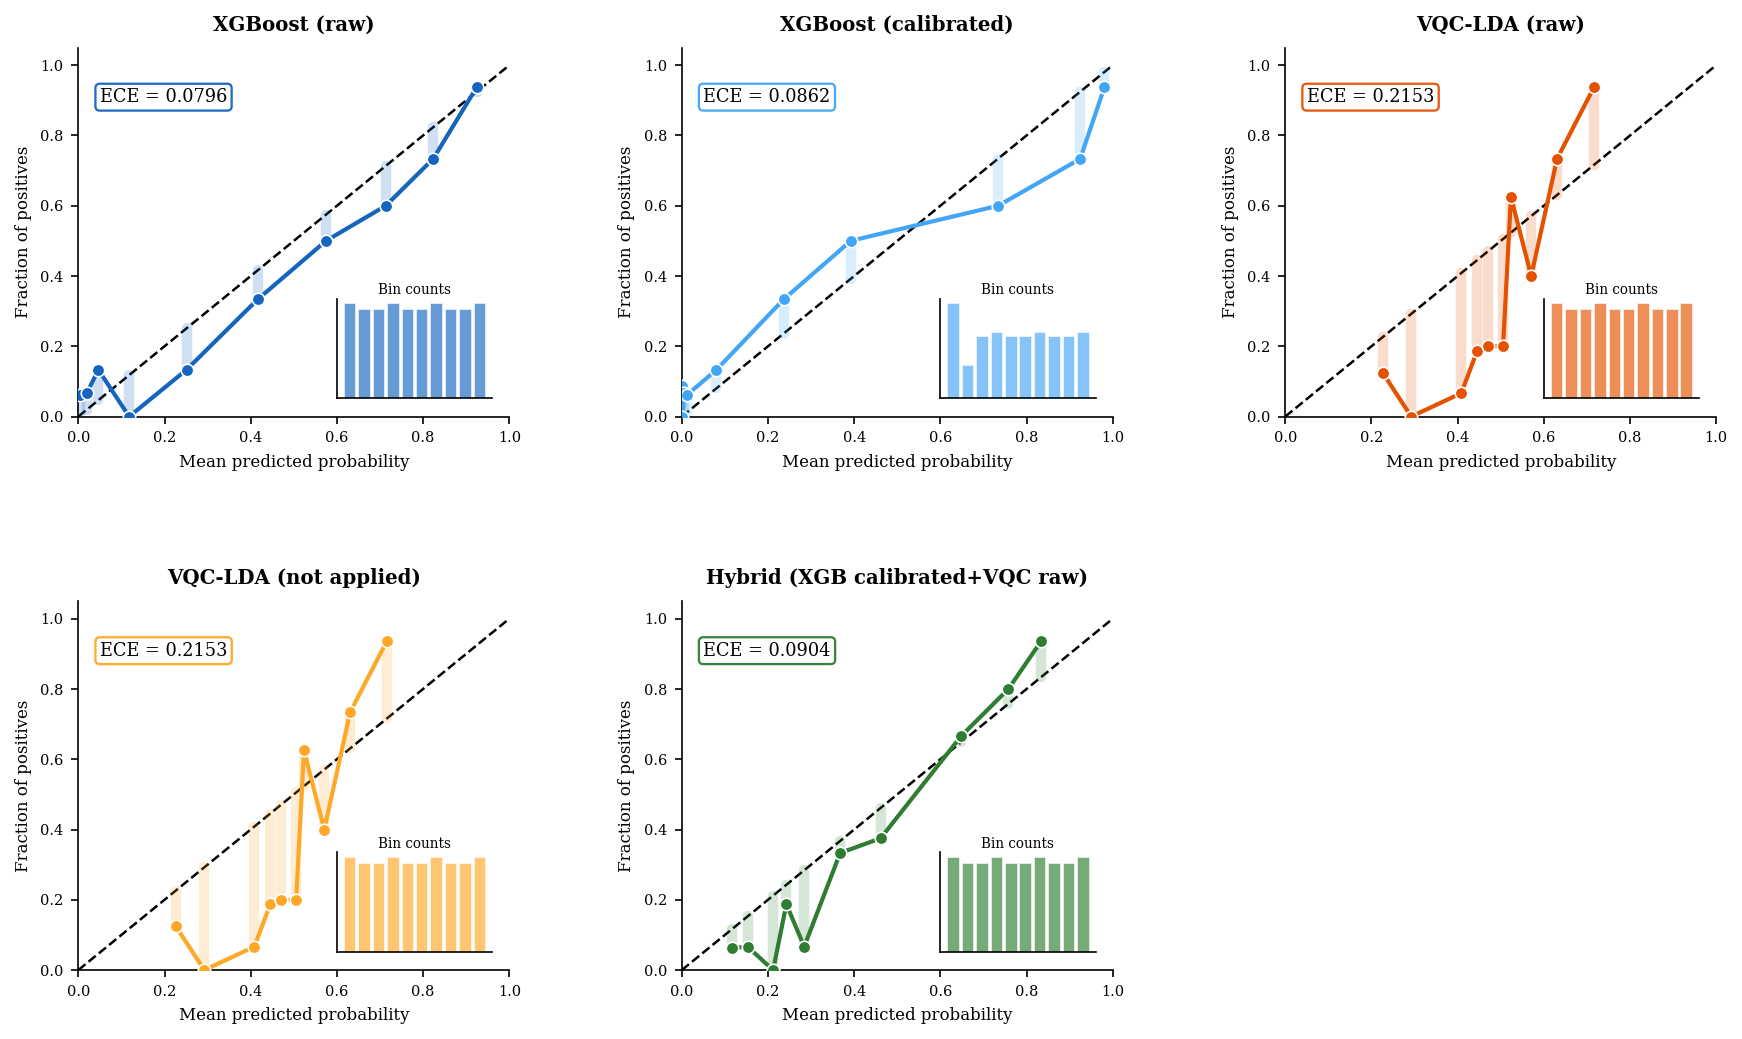

Saved:
..\figures\Supplementary_Figure_S1.pdf
..\figures\Supplementary_Figure_S1.png


In [5]:


def get_reliability_data(y_true, y_prob, n_bins=10, strategy='quantile'):
    """Return bin-level calibration data for plotting."""
    if strategy == 'quantile':
        quantiles = np.linspace(0, 1, n_bins + 1)
        bins = np.percentile(y_prob, quantiles * 100)
    else:
        bins = np.linspace(0, 1, n_bins + 1)

    conf_vals, acc_vals, counts = [], [], []
    for i in range(len(bins) - 1):
        mask = (y_prob >= bins[i]) & (y_prob <= bins[i+1]) if i == 0 \
               else (y_prob > bins[i]) & (y_prob <= bins[i+1])
        if mask.sum() == 0:
            continue
        conf_vals.append(y_prob[mask].mean())
        acc_vals.append(y_true[mask].mean())
        counts.append(mask.sum())
    return np.array(conf_vals), np.array(acc_vals), np.array(counts)


def draw_reliability_panel(ax, y_true, y_prob, color, label, n_bins=10):
    """Draw a clean single reliability diagram panel."""
    
    conf, acc, counts = get_reliability_data(
        y_true, y_prob, n_bins=n_bins
    )
    ece, _ = compute_ece(
        y_true, y_prob, n_bins=n_bins
    )

    # Perfect calibration line
    ax.plot(
        [0, 1], [0, 1],
        'k--',
        lw=1.2,
        zorder=1
    )

    # Calibration gaps
    for c, a in zip(conf, acc):
        ax.plot(
            [c, c], [c, a],
            color=color,
            alpha=0.20,
            lw=5,
            solid_capstyle='round'
        )

    # Reliability curve
    ax.plot(
        conf,
        acc,
        'o-',
        color=color,
        lw=2,
        ms=6,
        zorder=3,
        markeredgecolor='white',
        markeredgewidth=0.8
    )

    # ECE box — moved slightly lower/right
    ax.text(
        0.05,
        0.89,
        f'ECE = {ece:.4f}',
        transform=ax.transAxes,
        fontsize=8.5,
        va='top',
        ha='left',
        bbox=dict(
            boxstyle='round,pad=0.25',
            fc='white',
            ec=color,
            lw=1.1,
            alpha=0.95
        )
    )

    # Bin-count inset
    axins = ax.inset_axes([0.60, 0.05, 0.36, 0.27])

    axins.bar(
        range(len(counts)),
        counts,
        color=color,
        alpha=0.65,
        edgecolor='white',
        linewidth=0.4
    )

    axins.set_xticks([])
    axins.set_yticks([])
    axins.set_title(
        'Bin counts',
        fontsize=6.5,
        pad=2
    )

    axins.spines['top'].set_visible(False)
    axins.spines['right'].set_visible(False)

    # Axes formatting
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.05)

    ax.set_xticks(np.arange(0, 1.01, 0.2))
    ax.set_yticks(np.arange(0, 1.01, 0.2))

    ax.set_xlabel(
        'Mean predicted probability',
        fontsize=8
    )

    ax.set_ylabel(
        'Fraction of positives',
        fontsize=8
    )

    ax.tick_params(
        axis='both',
        labelsize=7
    )

    # KEEP YOUR ORIGINAL PANEL HEADING
    ax.set_title(
        label,
        fontsize=9.5,
        fontweight='bold',
        pad=8
    )

    # Cleaner borders
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)



panel_configs = [
    (xgb_raw,      '#1565C0', 'XGBoost (raw)'),
    (xgb_cal,      '#42A5F5', 'XGBoost (calibrated)'),
    (vqc_raw,      '#E65100', 'VQC-LDA (raw)'),
    (vqc_cal,      '#FFA726', 'VQC-LDA (not applied)'),
    (hybrid_score, '#2E7D32', 'Hybrid (XGB calibrated+VQC raw)'),
]

fig = plt.figure(figsize=(12, 7.5))

gs = gridspec.GridSpec(
    2, 3,
    figure=fig,
    hspace=0.50,
    wspace=0.40
)

axes = [
    fig.add_subplot(gs[0, 0]),
    fig.add_subplot(gs[0, 1]),
    fig.add_subplot(gs[0, 2]),
    fig.add_subplot(gs[1, 0]),
    fig.add_subplot(gs[1, 1]),
]

ax_empty = fig.add_subplot(gs[1, 2])
ax_empty.axis('off')

for ax, (probs, color, label) in zip(axes, panel_configs):
    draw_reliability_panel(
        ax,
        y_true,
        probs,
        color,
        label
    )

# Keep your overall title if you want it

# Adjust layout
plt.subplots_adjust(
    left=0.07,
    right=0.98,
    bottom=0.08,
    top=0.90
)

# Save PDF first
fig.savefig(
    FIG_DIR / "Supplementary_Figure_S1.pdf",
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.05,
    facecolor="white"
)

# Save PNG before plt.show()
fig.savefig(
    FIG_DIR / "Supplementary_Figure_S1.png",
    format="png",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.05,
    facecolor="white"
)

# Display only after both files are saved
plt.show()

print("Saved:")
print(FIG_DIR / "Supplementary_Figure_S1.pdf")
print(FIG_DIR / "Supplementary_Figure_S1.png")

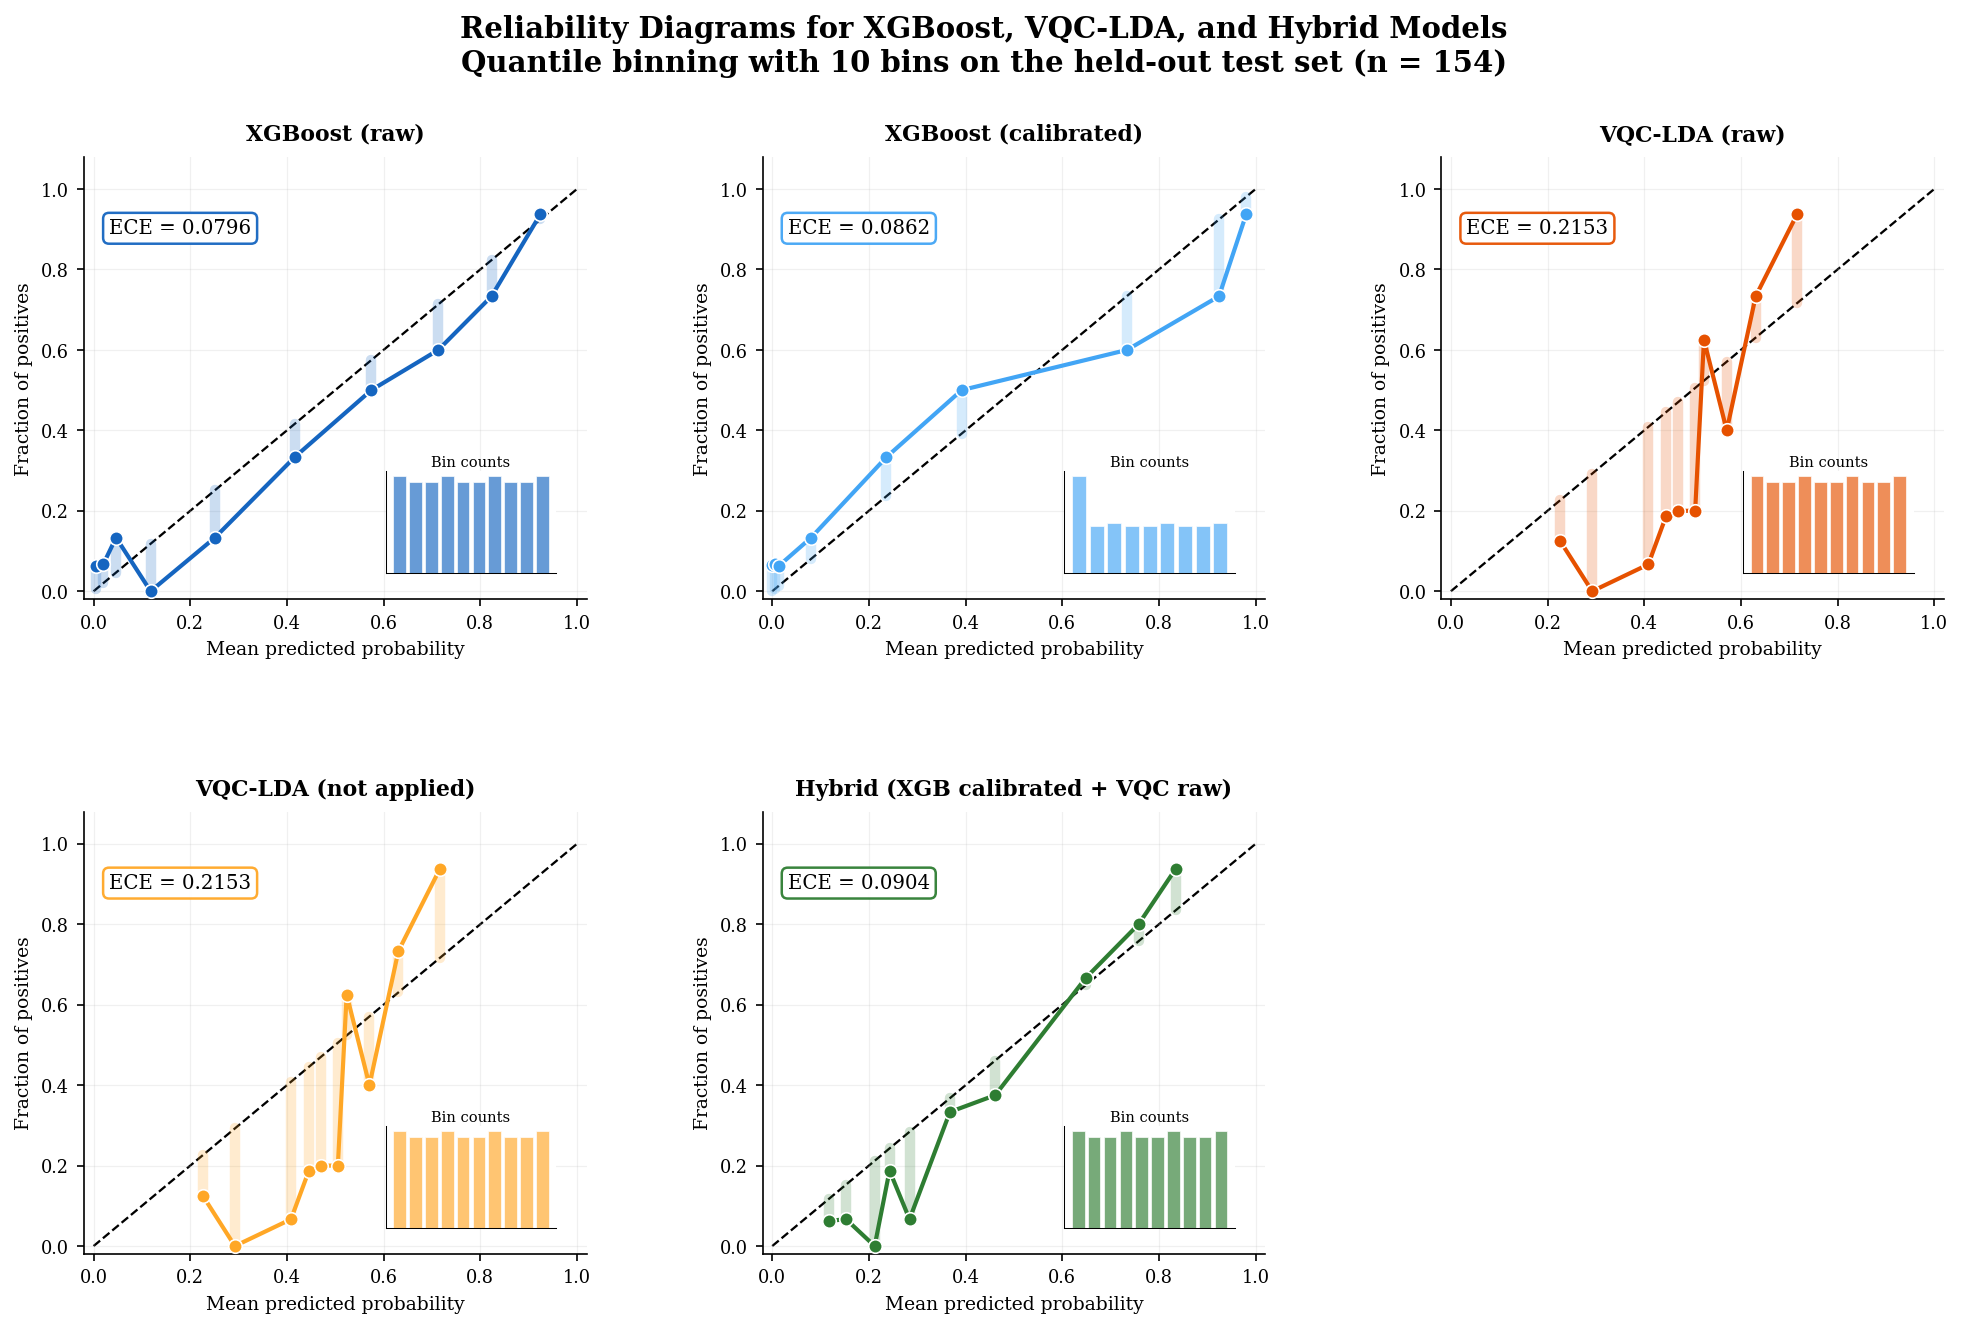

Saved: calibration_01_reliability_diagrams_clean.png


In [6]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

def get_reliability_data(y_true, y_prob, n_bins=10, strategy="quantile"):
    """Return bin-level calibration data for plotting."""
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)

    if strategy == "quantile":
        quantiles = np.linspace(0, 1, n_bins + 1)
        bins = np.percentile(y_prob, quantiles * 100)
        bins = np.unique(bins)
    else:
        bins = np.linspace(0, 1, n_bins + 1)

    conf_vals, acc_vals, counts = [], [], []

    for i in range(len(bins) - 1):
        if i == 0:
            mask = (y_prob >= bins[i]) & (y_prob <= bins[i + 1])
        else:
            mask = (y_prob > bins[i]) & (y_prob <= bins[i + 1])

        if mask.sum() == 0:
            continue

        conf_vals.append(y_prob[mask].mean())
        acc_vals.append(y_true[mask].mean())
        counts.append(mask.sum())

    return np.array(conf_vals), np.array(acc_vals), np.array(counts)


def draw_reliability_panel(ax, y_true, y_prob, color, label, n_bins=10):
    """Draw a clean reliability diagram panel."""
    conf, acc, counts = get_reliability_data(y_true, y_prob, n_bins=n_bins)
    ece, _ = compute_ece(y_true, y_prob, n_bins=n_bins)

    ax.plot([0, 1], [0, 1], "k--", lw=1.1, zorder=1)

    for c, a in zip(conf, acc):
        ax.plot(
            [c, c], [c, a],
            color=color,
            alpha=0.22,
            lw=5,
            solid_capstyle="round",
            zorder=2
        )

    ax.plot(
        conf, acc,
        "o-",
        color=color,
        lw=2,
        ms=6.5,
        zorder=3,
        markeredgecolor="white",
        markeredgewidth=0.8
    )

    # ECE box placed away from title and diagonal line
    ax.text(
        0.05, 0.86,
        f"ECE = {ece:.4f}",
        transform=ax.transAxes,
        fontsize=9.5,
        va="top",
        ha="left",
        bbox=dict(
            boxstyle="round,pad=0.30",
            fc="white",
            ec=color,
            lw=1.2,
            alpha=0.95
        )
    )

    # Small inset histogram for bin counts
    axins = ax.inset_axes([0.60, 0.06, 0.34, 0.23])
    axins.bar(
        range(len(counts)),
        counts,
        color=color,
        alpha=0.65,
        edgecolor="white",
        linewidth=0.5
    )
    axins.set_xticks([])
    axins.set_yticks([])
    axins.set_title("Bin counts", fontsize=7, pad=2)

    for spine in axins.spines.values():
        spine.set_linewidth(0.5)

    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.02, 1.08)
    ax.set_xlabel("Mean predicted probability", fontsize=9)
    ax.set_ylabel("Fraction of positives", fontsize=9)
    ax.set_title(label, fontsize=10.5, fontweight="bold", pad=8)

    ax.tick_params(axis="both", labelsize=8.5)
    ax.grid(alpha=0.18, linewidth=0.6)


panel_configs = [
    (xgb_raw,      "#1565C0", "XGBoost (raw)"),
    (xgb_cal,      "#42A5F5", "XGBoost (calibrated)"),
    (vqc_raw,      "#E65100", "VQC-LDA (raw)"),
    (vqc_cal,      "#FFA726", "VQC-LDA (not applied)"),
    (hybrid_score, "#2E7D32", "Hybrid (XGB calibrated + VQC raw)")
]

fig = plt.figure(figsize=(16, 9.5))
gs = gridspec.GridSpec(
    2, 3,
    figure=fig,
    hspace=0.48,
    wspace=0.35
)

axes = [
    fig.add_subplot(gs[0, 0]),
    fig.add_subplot(gs[0, 1]),
    fig.add_subplot(gs[0, 2]),
    fig.add_subplot(gs[1, 0]),
    fig.add_subplot(gs[1, 1])
]

ax_empty = fig.add_subplot(gs[1, 2])
ax_empty.axis("off")

for ax, (probs, color, label) in zip(axes, panel_configs):
    draw_reliability_panel(ax, y_true, probs, color, label, n_bins=10)

fig.suptitle(
    "Reliability Diagrams for XGBoost, VQC-LDA, and Hybrid Models\n"
    "Quantile binning with 10 bins on the held-out test set (n = 154)",
    fontsize=14,
    fontweight="bold",
    y=0.98
)

plt.savefig(
    FIG_DIR / "calibration_01_reliability_diagrams_clean.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Saved: calibration_01_reliability_diagrams_clean.png")

In [7]:
print("=== VQC Probability Range Analysis ===\n")
print(f"VQC raw probability range: [{vqc_raw.min():.4f}, {vqc_raw.max():.4f}]")
print(f"VQC raw probability span:  {vqc_raw.max() - vqc_raw.min():.4f}")
print(f"XGB raw probability range: [{xgb_raw.min():.4f}, {xgb_raw.max():.4f}]")
print(f"XGB raw probability span:  {xgb_raw.max() - xgb_raw.min():.4f}")
print()


for cls, label in [(0, 'Non-diabetic'), (1, 'Diabetic')]:
    mask = y_true == cls
    print(f"{label} (n={mask.sum()}):")
    print(f"  VQC proba — mean: {vqc_raw[mask].mean():.4f}, "
          f"std: {vqc_raw[mask].std():.4f}, "
          f"range: [{vqc_raw[mask].min():.4f}, {vqc_raw[mask].max():.4f}]")
    print(f"  XGB proba — mean: {xgb_raw[mask].mean():.4f}, "
          f"std: {xgb_raw[mask].std():.4f}, "
          f"range: [{xgb_raw[mask].min():.4f}, {xgb_raw[mask].max():.4f}]")
    print()


vqc_range = vqc_raw.max() - vqc_raw.min()
max_vqc_contribution = 0.5 * vqc_range
print(f"Maximum possible VQC contribution to hybrid score (0.5 weight):")
print(f"  0.5 × {vqc_range:.4f} = {max_vqc_contribution:.4f}")
print(f"  This means VQC can shift the hybrid score by at most ±{max_vqc_contribution/2:.4f}")
print()
print("Scientific interpretation:")
print(f"The VQC probability range [{vqc_raw.min():.4f}, {vqc_raw.max():.4f}] indicates the quantum circuit")
print("produces outputs clustered in the central probability band rather than")
print("approaching 0 or 1 confidently. This reflects quantum circuit expressibility")
print("limitations and the effect of angle encoding compression on probability space.")

=== VQC Probability Range Analysis ===

VQC raw probability range: [0.2041, 0.7980]
VQC raw probability span:  0.5939
XGB raw probability range: [0.0023, 0.9625]
XGB raw probability span:  0.9602

Non-diabetic (n=100):
  VQC proba — mean: 0.4223, std: 0.1207, range: [0.2041, 0.7430]
  XGB proba — mean: 0.2300, std: 0.2521, range: [0.0023, 0.8974]

Diabetic (n=54):
  VQC proba — mean: 0.5839, std: 0.1177, range: [0.2224, 0.7980]
  XGB proba — mean: 0.6853, std: 0.2634, range: [0.0074, 0.9625]

Maximum possible VQC contribution to hybrid score (0.5 weight):
  0.5 × 0.5939 = 0.2970
  This means VQC can shift the hybrid score by at most ±0.1485

Scientific interpretation:
The VQC probability range [0.2041, 0.7980] indicates the quantum circuit
produces outputs clustered in the central probability band rather than
approaching 0 or 1 confidently. This reflects quantum circuit expressibility
limitations and the effect of angle encoding compression on probability space.


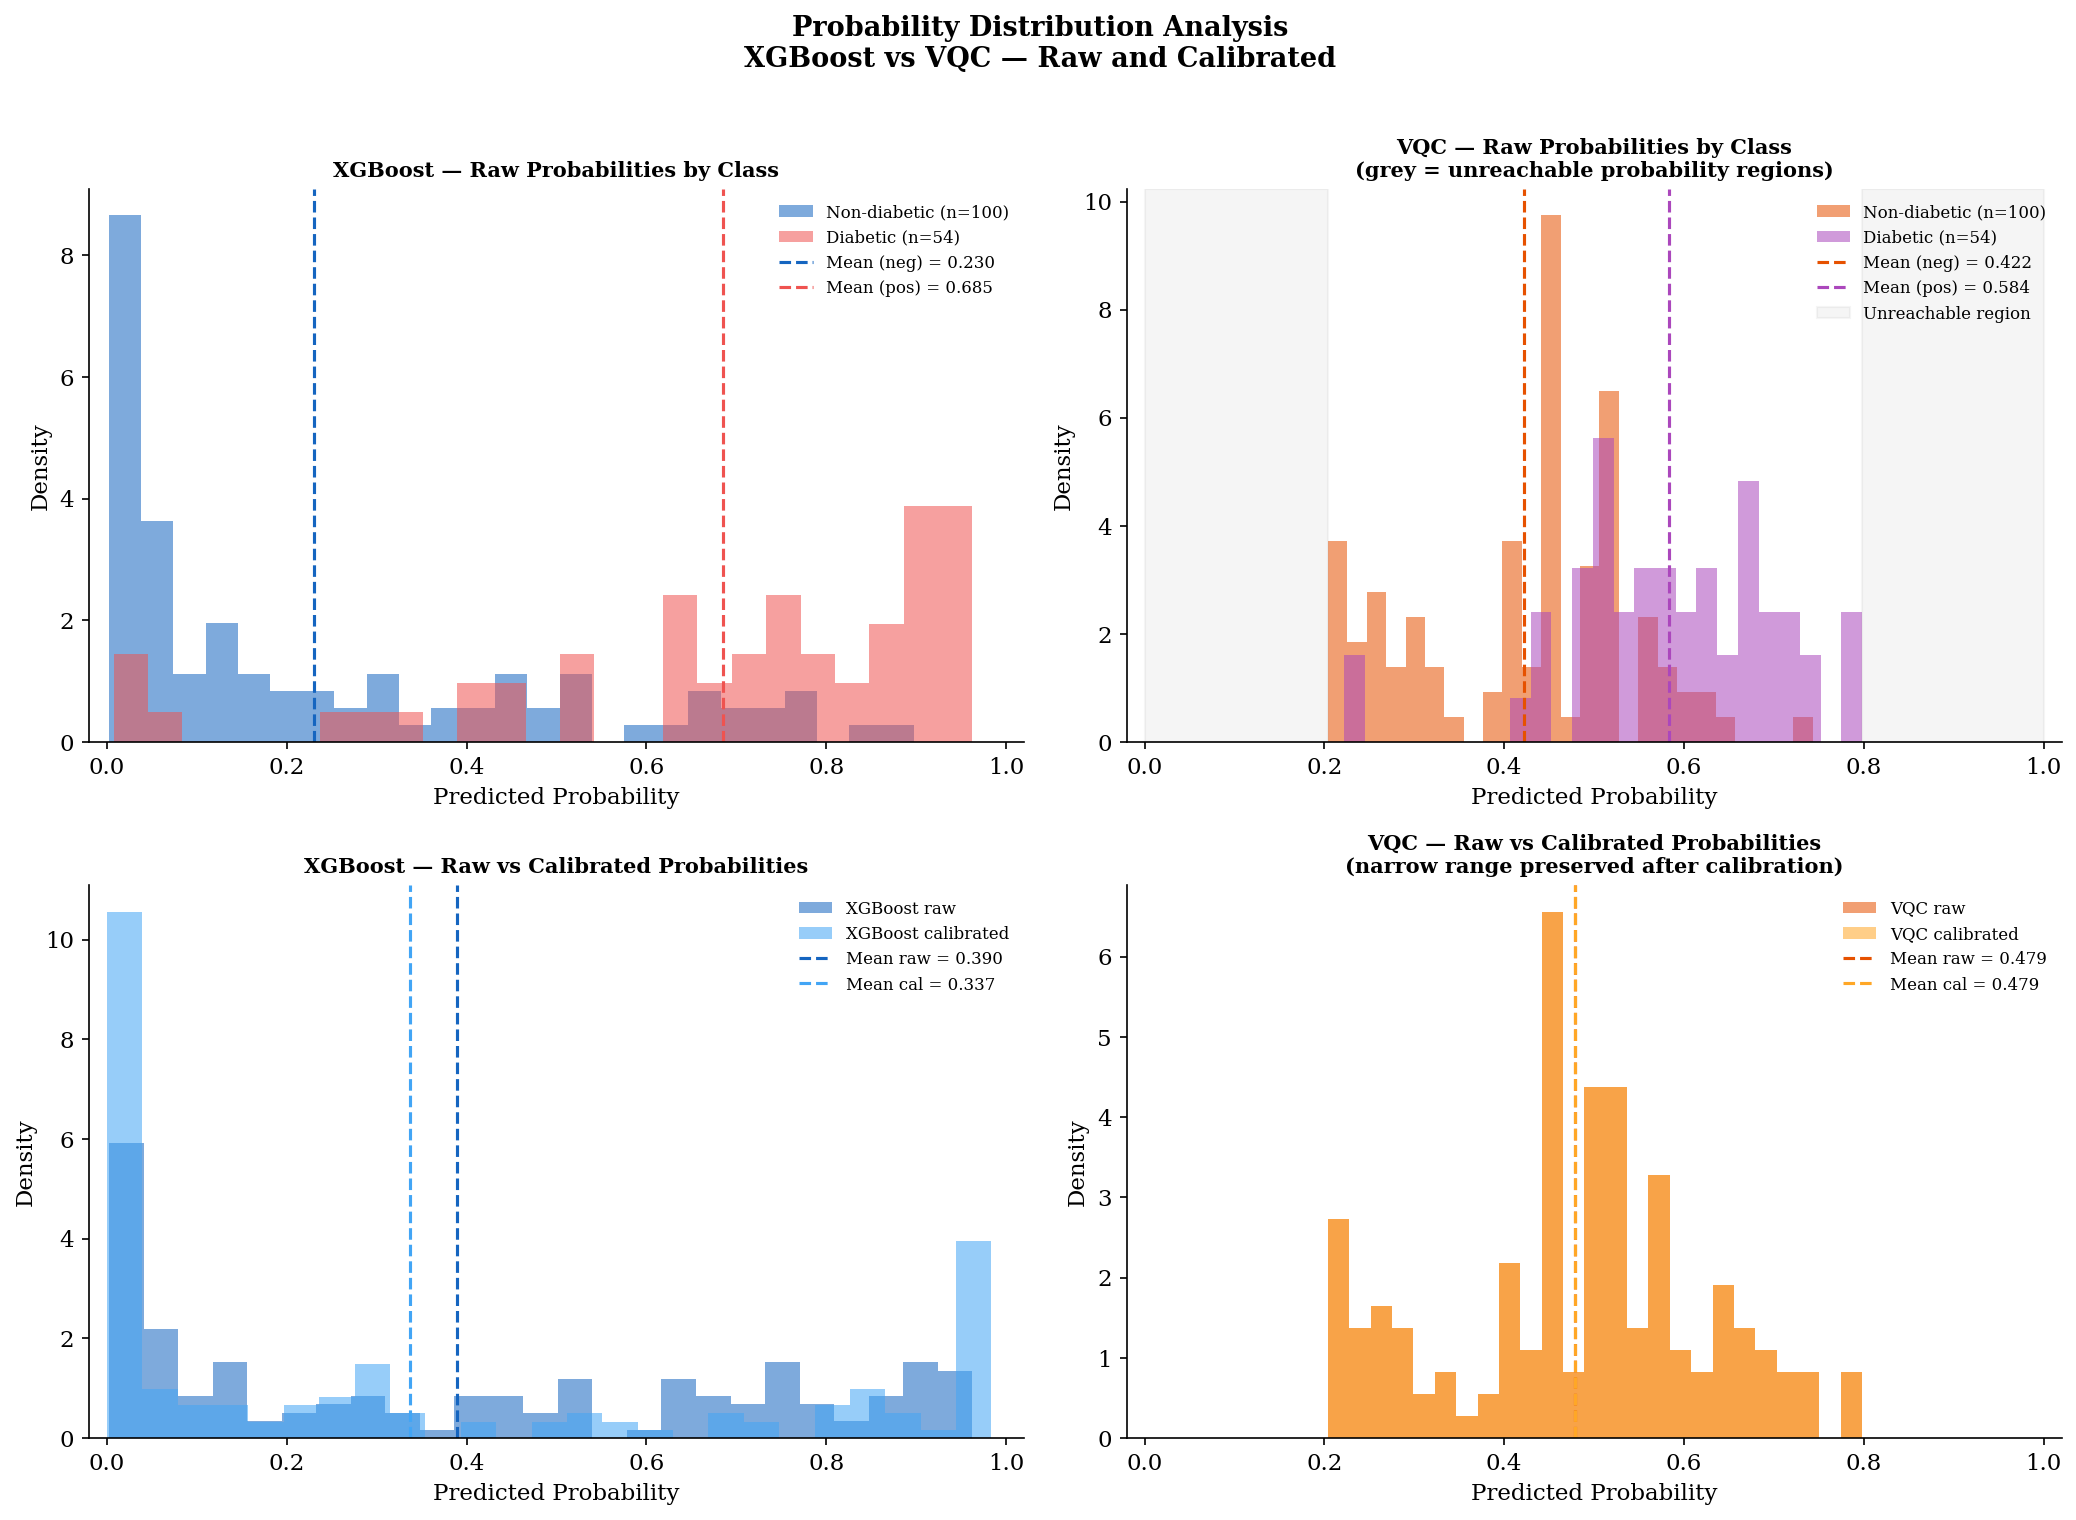

Saved: calibration_02_probability_distributions.png


In [8]:

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Probability Distribution Analysis\nXGBoost vs VQC — Raw and Calibrated',
             fontsize=13, fontweight='bold', y=1.01)

palette = {
    'neg_raw':  '#1565C0',   
    'pos_raw':  '#EF5350',   
    'neg_vqc':  '#E65100',   
    'pos_vqc':  '#AB47BC',  
    'xgb_raw':  '#1565C0',
    'xgb_cal':  '#42A5F5',
    'vqc_raw':  '#E65100',
    'vqc_cal':  '#FFA726',
}

bins_hist = 25


ax = axes[0, 0]
mask0, mask1 = y_true == 0, y_true == 1
ax.hist(xgb_raw[mask0], bins=bins_hist, alpha=0.55, color=palette['neg_raw'],
        label=f'Non-diabetic (n={mask0.sum()})', density=True)
ax.hist(xgb_raw[mask1], bins=bins_hist, alpha=0.55, color=palette['pos_raw'],
        label=f'Diabetic (n={mask1.sum()})', density=True)
ax.axvline(xgb_raw[mask0].mean(), color=palette['neg_raw'], ls='--', lw=1.5,
           label=f'Mean (neg) = {xgb_raw[mask0].mean():.3f}')
ax.axvline(xgb_raw[mask1].mean(), color=palette['pos_raw'],  ls='--', lw=1.5,
           label=f'Mean (pos) = {xgb_raw[mask1].mean():.3f}')
ax.set_title('XGBoost — Raw Probabilities by Class', fontweight='bold', fontsize=10)
ax.set_xlabel('Predicted Probability')
ax.set_ylabel('Density')
ax.legend(fontsize=8, frameon=False)
ax.set_xlim(-0.02, 1.02)


ax = axes[0, 1]
ax.hist(vqc_raw[mask0], bins=bins_hist, alpha=0.55, color=palette['neg_vqc'],
        label=f'Non-diabetic (n={mask0.sum()})', density=True)
ax.hist(vqc_raw[mask1], bins=bins_hist, alpha=0.55, color=palette['pos_vqc'],
        label=f'Diabetic (n={mask1.sum()})', density=True)
ax.axvline(vqc_raw[mask0].mean(), color=palette['neg_vqc'], ls='--', lw=1.5,
           label=f'Mean (neg) = {vqc_raw[mask0].mean():.3f}')
ax.axvline(vqc_raw[mask1].mean(), color=palette['pos_vqc'],  ls='--', lw=1.5,
           label=f'Mean (pos) = {vqc_raw[mask1].mean():.3f}')
ax.axvspan(0.0, vqc_raw.min(), alpha=0.08, color='grey', label='Unreachable region')
ax.axvspan(vqc_raw.max(), 1.0, alpha=0.08, color='grey')
ax.set_title('VQC — Raw Probabilities by Class\n(grey = unreachable probability regions)',
             fontweight='bold', fontsize=10)
ax.set_xlabel('Predicted Probability')
ax.set_ylabel('Density')
ax.legend(fontsize=8, frameon=False)
ax.set_xlim(-0.02, 1.02)


ax = axes[1, 0]
ax.hist(xgb_raw, bins=bins_hist, alpha=0.55, color=palette['xgb_raw'],
        label='XGBoost raw', density=True)
ax.hist(xgb_cal, bins=bins_hist, alpha=0.55, color=palette['xgb_cal'],
        label='XGBoost calibrated', density=True)
ax.axvline(xgb_raw.mean(), color=palette['xgb_raw'], ls='--', lw=1.5,
           label=f'Mean raw = {xgb_raw.mean():.3f}')
ax.axvline(xgb_cal.mean(), color=palette['xgb_cal'],  ls='--', lw=1.5,
           label=f'Mean cal = {xgb_cal.mean():.3f}')
ax.set_title('XGBoost — Raw vs Calibrated Probabilities', fontweight='bold', fontsize=10)
ax.set_xlabel('Predicted Probability')
ax.set_ylabel('Density')
ax.legend(fontsize=8, frameon=False)
ax.set_xlim(-0.02, 1.02)


ax = axes[1, 1]
ax.hist(vqc_raw, bins=bins_hist, alpha=0.55, color=palette['vqc_raw'],
        label='VQC raw', density=True)
ax.hist(vqc_cal, bins=bins_hist, alpha=0.55, color=palette['vqc_cal'],
        label='VQC calibrated', density=True)
ax.axvline(vqc_raw.mean(), color=palette['vqc_raw'], ls='--', lw=1.5,
           label=f'Mean raw = {vqc_raw.mean():.3f}')
ax.axvline(vqc_cal.mean(), color=palette['vqc_cal'],  ls='--', lw=1.5,
           label=f'Mean cal = {vqc_cal.mean():.3f}')
ax.set_title('VQC — Raw vs Calibrated Probabilities\n(narrow range preserved after calibration)',
             fontweight='bold', fontsize=10)
ax.set_xlabel('Predicted Probability')
ax.set_ylabel('Density')
ax.legend(fontsize=8, frameon=False)
ax.set_xlim(-0.02, 1.02)

plt.tight_layout()
plt.savefig(FIG_DIR / 'calibration_02_probability_distributions.png',
            dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: calibration_02_probability_distributions.png")

In [9]:
print(df_cal['Model'].tolist())

['XGBoost (raw)', 'XGBoost (calibrated)', 'VQC (raw)', 'VQC (no calibration)', 'Hybrid (calibrated)']


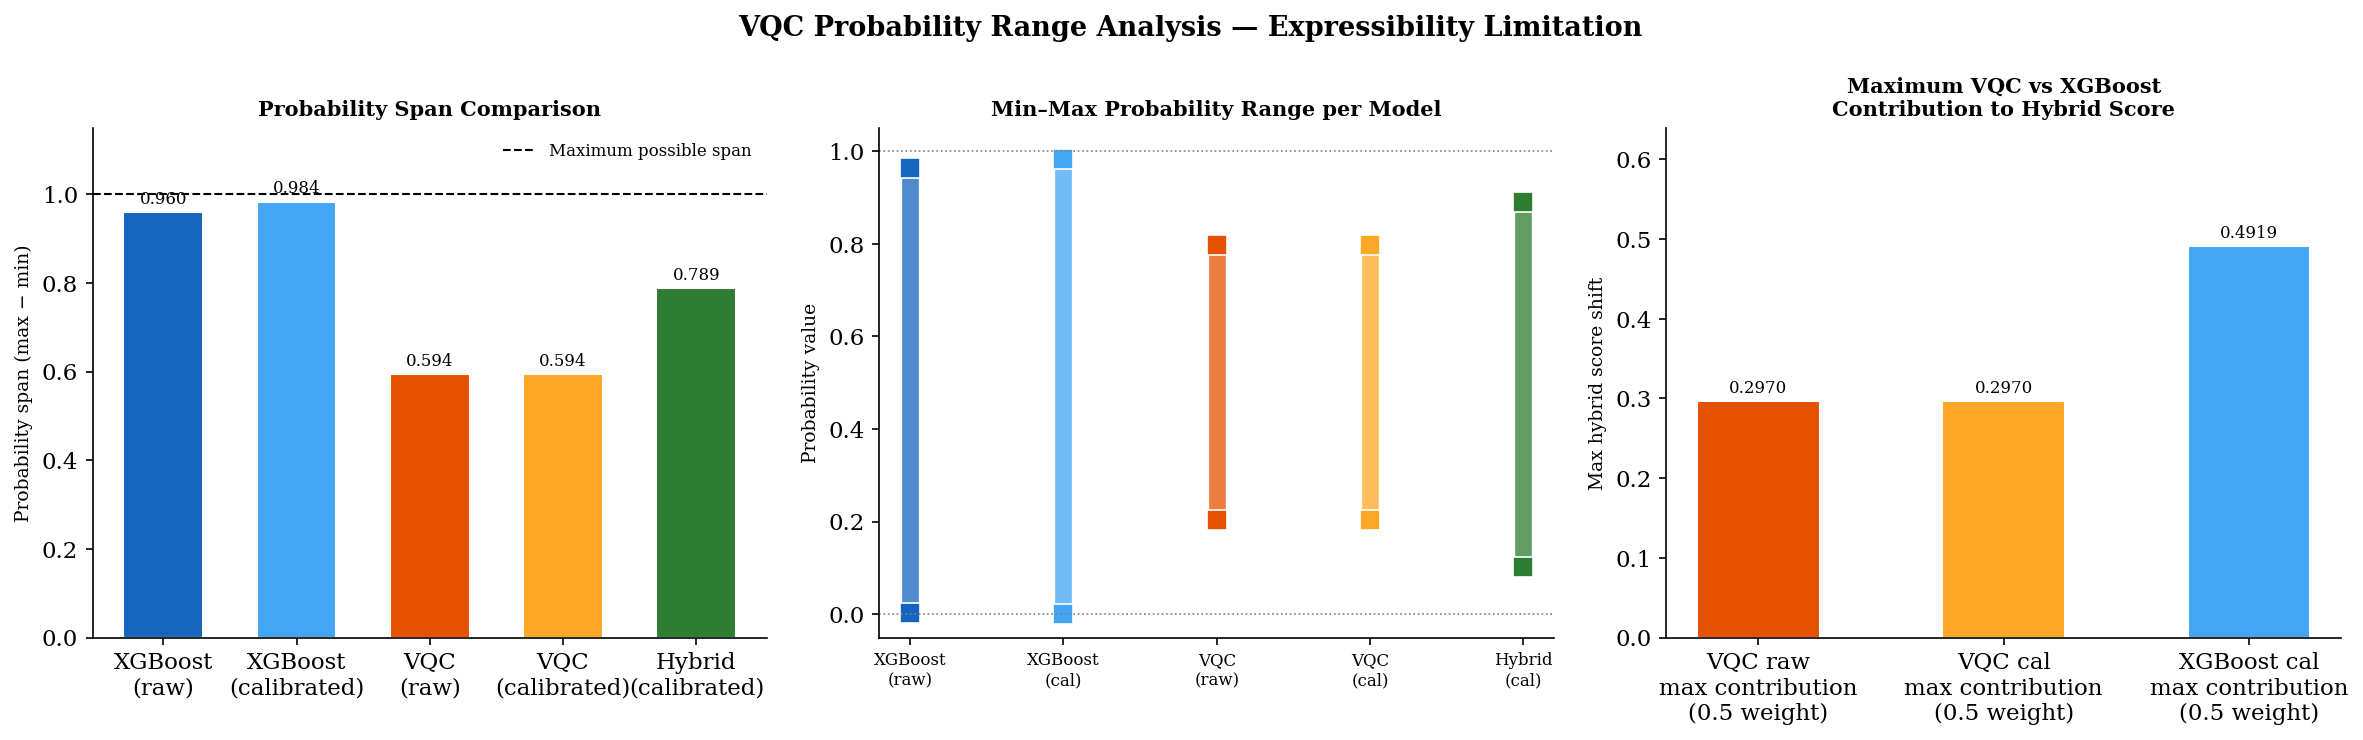

Saved: calibration_03_vqc_range_analysis.png

FINAL CALIBRATION SUMMARY
Test set: 154 samples | 100 non-diabetic | 54 diabetic | 35.1% positive rate
Calibration method: Quantile binning (10 bins) fitted on TRAIN (n=614), applied to TEST
ECE strategy: quantile (equal-frequency) bins, n_bins=10

               Model    ECE  Brier Score  ROC-AUC Interpretation
       XGBoost (raw) 0.0796       0.1347    87.33           Good
XGBoost (calibrated) 0.0862       0.1362    87.48           Good
           VQC (raw) 0.2153       0.1908    84.07           Poor
VQC (no calibration) 0.2153       0.1908    84.07           Poor
 Hybrid (calibrated) 0.0904       0.1359    88.13           Good

Figures saved to:
  ..\figures\calibration_01_reliability_diagrams.png
  ..\figures\calibration_02_probability_distributions.png
  ..\figures\calibration_03_vqc_range_analysis.png

Tables saved to:
  ..\tables\calibration_metrics.csv

Key findings:
  1. VQC raw probability range [0.2041, 0.7980] — span 0.5939
  2

In [10]:

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('VQC Probability Range Analysis — Expressibility Limitation',
             fontsize=13, fontweight='bold')

#
ax = axes[0]
spans = {
    'XGBoost\n(raw)':        xgb_raw.max() - xgb_raw.min(),
    'XGBoost\n(calibrated)': xgb_cal.max() - xgb_cal.min(),
    'VQC\n(raw)':            vqc_raw.max() - vqc_raw.min(),
    'VQC\n(calibrated)':     vqc_cal.max() - vqc_cal.min(),
    'Hybrid\n(calibrated)':  hybrid_score.max() - hybrid_score.min(),
}
colors_span = ['#1565C0', '#42A5F5', '#E65100', '#FFA726', '#2E7D32']
bars = ax.bar(list(spans.keys()), list(spans.values()), color=colors_span,
               edgecolor='white', lw=1, width=0.6)
ax.axhline(1.0, color='black', ls='--', lw=1, label='Maximum possible span')
ax.set_ylim(0, 1.15)
ax.set_ylabel('Probability span (max − min)', fontsize=9)
ax.set_title('Probability Span Comparison', fontweight='bold', fontsize=10)
ax.legend(fontsize=8, frameon=False)
for bar, val in zip(bars, spans.values()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{val:.3f}', ha='center', va='bottom', fontsize=8)


ax = axes[1]
model_names  = ['XGBoost\n(raw)', 'XGBoost\n(cal)', 'VQC\n(raw)', 'VQC\n(cal)', 'Hybrid\n(cal)']
prob_mins    = [xgb_raw.min(), xgb_cal.min(), vqc_raw.min(), vqc_cal.min(), hybrid_score.min()]
prob_maxs    = [xgb_raw.max(), xgb_cal.max(), vqc_raw.max(), vqc_cal.max(), hybrid_score.max()]
colors_range = ['#1565C0', '#42A5F5', '#E65100', '#FFA726', '#2E7D32']

for i, (name, lo, hi, c) in enumerate(zip(model_names, prob_mins, prob_maxs, colors_range)):
    ax.plot([i, i], [lo, hi], color=c, lw=8, solid_capstyle='round', alpha=0.75)
    ax.plot(i, lo, 's', color=c, ms=10, markeredgecolor='white', markeredgewidth=0.8)
    ax.plot(i, hi, 's', color=c, ms=10, markeredgecolor='white', markeredgewidth=0.8)

ax.set_xticks(range(len(model_names)))
ax.set_xticklabels(model_names, fontsize=8)
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel('Probability value', fontsize=9)
ax.set_title('Min–Max Probability Range per Model', fontweight='bold', fontsize=10)
ax.axhline(0.0, color='grey', ls=':', lw=0.8)
ax.axhline(1.0, color='grey', ls=':', lw=0.8)


ax = axes[2]
vqc_range_val = vqc_raw.max() - vqc_raw.min()
cal_range_val = vqc_cal.max() - vqc_cal.min()
categories = [
    'VQC raw\nmax contribution\n(0.5 weight)',      # ← was 0.2
    'VQC cal\nmax contribution\n(0.5 weight)',      # ← was 0.2
    'XGBoost cal\nmax contribution\n(0.5 weight)', # ← was 0.8
]
contributions = [
    0.5 * vqc_range_val,                           # ← was 0.2
    0.5 * cal_range_val,                           # ← was 0.2
    0.5 * (xgb_cal.max() - xgb_cal.min()),        # ← was 0.8
]
bar_colors = ['#E65100', '#FFA726', '#42A5F5']
bars2 = ax.bar(categories, contributions, color=bar_colors,
               edgecolor='white', lw=1, width=0.5)
ax.set_ylim(0, max(contributions) * 1.3)
ax.set_ylabel('Max hybrid score shift', fontsize=9)
ax.set_title('Maximum VQC vs XGBoost\nContribution to Hybrid Score',
             fontweight='bold', fontsize=10)
for bar, val in zip(bars2, contributions):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{val:.4f}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig(FIG_DIR / 'calibration_03_vqc_range_analysis.png',
            dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: calibration_03_vqc_range_analysis.png")


vqc_span     = vqc_raw.max() - vqc_raw.min()
xgb_span     = xgb_raw.max() - xgb_raw.min()

print("\n" + "="*72)
print("FINAL CALIBRATION SUMMARY")
print("="*72)
print(f"Test set: 154 samples | 100 non-diabetic | 54 diabetic | 35.1% positive rate")
print(f"Calibration method: Quantile binning (10 bins) fitted on TRAIN (n=614), applied to TEST")
print(f"ECE strategy: quantile (equal-frequency) bins, n_bins=10")
print()
print(df_cal.to_string(index=False))
print()
print("Figures saved to:")
for fname in [
    'calibration_01_reliability_diagrams.png',
    'calibration_02_probability_distributions.png',
    'calibration_03_vqc_range_analysis.png',
]:
    print(f"  {FIG_DIR / fname}")
print()
print("Tables saved to:")
print(f"  {TAB_DIR / 'calibration_metrics.csv'}")
print()


hybrid_row  = df_cal[df_cal['Model'] == 'Hybrid (calibrated)'].iloc[0]
vqc_cal_row = df_cal[df_cal['Model'] == 'VQC (no calibration)'].iloc[0]
xgb_cal_row = df_cal[df_cal['Model'] == 'XGBoost (calibrated)'].iloc[0]

print("Key findings:")
print(f"  1. VQC raw probability range [{vqc_raw.min():.4f}, {vqc_raw.max():.4f}]"
      f" — span {vqc_span:.4f}")
print(f"  2. Maximum VQC contribution to hybrid (0.5 weight)"
      f" = 0.5 × {vqc_span:.4f} = {0.5*vqc_span:.4f} units")
print(f"  3. XGB ECE: {df_cal[df_cal['Model']=='XGBoost (raw)'].iloc[0]['ECE']:.4f}"
      f" → {xgb_cal_row['ECE']:.4f} (train/test distribution shift)")
print(f"     VQC calibration not applied — non-monotonic mapping detected in training data")
print(f"  4. Hybrid achieves ROC-AUC={hybrid_row['ROC-AUC']}%"
      f" | Brier={hybrid_row['Brier Score']}"
      f" | ECE={hybrid_row['ECE']}")
print(f"  5. Bin instability warning: ~15 samples/bin"
      f" — interpret ECE differences cautiously")